# Explainable BCI — training & artifact notebook
**Dataset:** BCI Competition IV-2a (`BNCI2014_001`, 9 subjects, 4 classes: left hand, right hand, feet, tongue)  
**Models:** (1) EEGNet · (2) CSP + LDA — both trained **per subject** (session *T* → train/val, session *E* → test)

Run the cells **top to bottom**. Everything that is needed to later *restart the runtime, load a new EEG signal, pick one or both models and generate explanations without retraining* is written to Google Drive.

**Designed to be robust**
- Fully **resumable**: finished subjects/models are skipped; interrupted EEGNet training resumes from `last_checkpoint.pth`.
- **OOM-safe**: small data footprint (one subject in RAM at a time), automatic batch-size halving on CUDA OOM, CPU fallback, chunked attribution.
- Artifacts are written **atomically** (tmp file → rename) so a runtime disconnect never leaves a half-written file.

**Artifact map (Drive folder `XBCI_BNCI2014_001/`)**

| Folder | Content |
|---|---|
| `code/` | `xbci_core.py` (models, preprocessing, explanation code — import it from the Streamlit app) |
| `env/` | `versions.json`, `requirements_freeze.txt`, `gpu_info.txt`, `experiment_config.json` |
| `raw_mne_data/` | raw BNCI2014_001 `.mat` files (downloaded by MOABB) |
| `data_processed/` | preprocessed epochs per subject (`.npz`), trial metadata, info |
| `reference/` | channel names/order, electrode coordinates, bands, event timings, class map, filters, reference, baseline statistics |
| `models/eegnet/subject_XX/` | weights, best+last checkpoint (+optimizer), history, config, normalisation, layer weights, graph, TorchScript, status |
| `models/csp_lda/subject_XX/` | sklearn pipeline, CSP filters/patterns, LDA coef/intercept, config, status |
| `experiments/subject_XX/` | predictions, metrics, split indices, explanations (IG, channel/time/frequency/TF), activations, comparison, baseline pool |


## 1 · Mount Drive & install packages

In [1]:
#@title Mount Google Drive (falls back to local disk if it fails)
import os
USE_DRIVE = True
ROOT = "/content/drive/MyDrive/XBCI_BNCI2014_001"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive mount failed -> using local /content/XBCI_BNCI2014_001 (NOT persistent!):", e)
        ROOT = "/content/XBCI_BNCI2014_001"
else:
    ROOT = "/content/XBCI_BNCI2014_001"
os.makedirs(ROOT, exist_ok=True)
print("Artifact root:", ROOT)

Mounted at /content/drive
Artifact root: /content/drive/MyDrive/XBCI_BNCI2014_001


In [2]:
#@title Install dependencies (≈1-2 min). If Colab asks to restart the runtime, restart, then re-run from cell 1.
import subprocess, sys
def pip(*pkgs):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
    return r.returncode
pip("moabb", "mne", "scikit-learn", "scipy", "pandas", "matplotlib", "joblib")
import importlib, numpy
for m in ["torch", "mne", "moabb", "sklearn", "scipy", "pandas"]:
    importlib.import_module(m)
print("numpy", numpy.__version__, "- imports OK")

numpy 2.4.6 - imports OK


## 2 · Core library (written to Drive so the Streamlit app can import the exact same code)

In [3]:
#@title Write xbci_core.py (collapsed - ~1200 lines, tested)
from pathlib import Path
Path("/content/xbci_core.py").write_text(r'''"""xbci_core.py - Explainable-BCI core library (BNCI2014_001 / BCI-IV-2a).

Used by the training notebook AND (later) by the Streamlit app.
Contains: models (EEGNet, CSP+LDA as torch module), data loading, training with
resume + OOM protection, artifact saving/loading, attribution / explanation
tools, comparison metrics, plotting helpers and an artifact audit.
"""
import os, json, gc, time, copy, hashlib, random, platform, sys, subprocess, warnings
import datetime as dt
from collections import OrderedDict
from pathlib import Path

import numpy as np
import torch
warnings.filterwarnings("ignore", message=".*torch.jit.trace.*")
warnings.filterwarnings("ignore", message=".*not writable.*")
import torch.nn as nn

CORE_VERSION = "1.0.0"
DATASET_NAME = "BNCI2014_001"
CLASS_NAMES = ["feet", "left_hand", "right_hand", "tongue"]      # index = label id
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
BNCI_EVENT_CODES = {"left_hand": 1, "right_hand": 2, "feet": 3, "tongue": 4}
STD_CHANNELS_2A = ["Fz", "FC3", "FC1", "FCz", "FC2", "FC4", "C5", "C3", "C1", "Cz", "C2",
                   "C4", "C6", "CP3", "CP1", "CPz", "CP2", "CP4", "P1", "Pz", "P2", "POz"]
FREQ_BANDS = OrderedDict([("theta", (4, 8)), ("mu", (8, 13)), ("beta_low", (13, 20)),
                          ("beta_high", (20, 30)), ("gamma_low", (30, 38))])

DEFAULT_CFG = {
    "seed": 42,
    "subjects": list(range(1, 10)),
    "preprocessing": {"fmin": 4.0, "fmax": 38.0, "tmin": 0.0, "tmax": None, "resample": 128,
                      "n_classes": 4, "unit_scale_to_uV": 1e6},
    "split": {"val_fraction": 0.2},
    "eegnet": {"F1": 8, "D": 2, "F2": 16, "kern_length": 64, "sep_kern": 16, "dropout": 0.5,
               "lr": 1e-3, "weight_decay": 0.0, "batch_size": 32, "epochs": 300,
               "patience": 60, "min_delta": 1e-4, "lr_patience": 20, "lr_factor": 0.5,
               "ckpt_every": 10},
    "csp_lda": {"n_components": 8, "reg": "ledoit_wolf", "lda_solver": "lsqr",
                "lda_shrinkage": "auto"},
    "explain": {"splits": ["test"], "max_trials": None, "ig_steps": 32, "ig_baselines": 3,
                "baseline_pool_size": 32, "n_windows": 8, "n_act_per_class": 6,
                "batch_size": 8, "occlusion_batch": 128},
}


# ----------------------------------------------------------------------------
# generic utilities
# ----------------------------------------------------------------------------
def now_iso():
    return dt.datetime.now().isoformat(timespec="seconds")


class _NpEncoder(json.JSONEncoder):
    def default(self, o):
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, (set, tuple)):
            return list(o)
        return str(o)


def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, cls=_NpEncoder)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_npz(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "wb") as f:
        np.savez_compressed(f, **arrays)
    os.replace(tmp, path)


def save_torch(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=map_location)


def save_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def cleanup_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def is_oom(e):
    oom_cls = getattr(torch.cuda, "OutOfMemoryError", None)
    if oom_cls is not None and isinstance(e, oom_cls):
        return True
    return "out of memory" in str(e).lower()


def set_seed(seed, deterministic=True):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device(prefer_cuda=True):
    return torch.device("cuda" if (prefer_cuda and torch.cuda.is_available()) else "cpu")


def deep_update(base, new):
    out = copy.deepcopy(base)
    for k, v in (new or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = deep_update(out[k], v)
        else:
            out[k] = v
    return out


def collect_env_info():
    import importlib.metadata as im
    pk = ["torch", "numpy", "scipy", "scikit-learn", "mne", "moabb", "pandas", "matplotlib",
          "joblib", "shap", "captum", "h5py", "streamlit"]
    ver = {}
    for p in pk:
        try:
            ver[p] = im.version(p)
        except Exception:
            ver[p] = None
    info = {"python": sys.version, "platform": platform.platform(), "packages": ver,
            "core_version": CORE_VERSION, "timestamp": now_iso(),
            "cuda_available": torch.cuda.is_available(),
            "cuda_version": torch.version.cuda,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
    return info


class ArtifactPaths:
    def __init__(self, root):
        self.root = Path(root)
        self.code = self.root / "code"
        self.env = self.root / "env"
        self.raw = self.root / "raw_mne_data"
        self.data = self.root / "data_processed"
        self.reference = self.root / "reference"
        self.models = self.root / "models"
        self.experiments = self.root / "experiments"
        self.reports = self.root / "reports"

    def make_all(self):
        for p in [self.code, self.env, self.raw, self.data, self.reference, self.models,
                  self.experiments, self.reports]:
            p.mkdir(parents=True, exist_ok=True)

    def model_dir(self, model_name, sid):
        return self.models / model_name / f"subject_{sid:02d}"

    def exp_dir(self, sid):
        return self.experiments / f"subject_{sid:02d}"


# ----------------------------------------------------------------------------
# models
# ----------------------------------------------------------------------------
class EEGNet(nn.Module):
    """EEGNet-v4 (Lawhern et al. 2018). Input (B,1,C,T) -> logits (B,n_classes)."""
    LAYER_ORDER = ["conv_temporal", "bn1", "conv_depthwise", "bn2", "act1", "pool1", "drop1",
                   "conv_sep_depth", "conv_sep_point", "bn3", "act2", "pool2", "drop2",
                   "flatten", "classifier"]

    def __init__(self, n_chans, n_times, n_classes, F1=8, D=2, F2=16, kern_length=64,
                 sep_kern=16, dropout=0.5):
        super().__init__()
        self.conv_temporal = nn.Conv2d(1, F1, (1, kern_length), padding="same", bias=False)
        self.bn1 = nn.BatchNorm2d(F1)
        self.conv_depthwise = nn.Conv2d(F1, F1 * D, (n_chans, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F1 * D)
        self.act1 = nn.ELU()
        self.pool1 = nn.AvgPool2d((1, 4))
        self.drop1 = nn.Dropout(dropout)
        self.conv_sep_depth = nn.Conv2d(F1 * D, F1 * D, (1, sep_kern), groups=F1 * D,
                                        padding="same", bias=False)
        self.conv_sep_point = nn.Conv2d(F1 * D, F2, (1, 1), bias=False)
        self.bn3 = nn.BatchNorm2d(F2)
        self.act2 = nn.ELU()
        self.pool2 = nn.AvgPool2d((1, 8))
        self.drop2 = nn.Dropout(dropout)
        self.flatten = nn.Flatten()
        n_feat = F2 * ((n_times // 4) // 8)
        if n_feat < 1:
            raise ValueError("n_times too short for EEGNet pooling")
        self.classifier = nn.Linear(n_feat, n_classes)

    def forward(self, x):
        for name in self.LAYER_ORDER:
            x = getattr(self, name)(x)
        return x


def apply_max_norm(model):
    with torch.no_grad():
        w = model.conv_depthwise.weight
        w.copy_(torch.renorm(w, p=2, dim=0, maxnorm=1.0))
        w = model.classifier.weight
        w.copy_(torch.renorm(w, p=2, dim=0, maxnorm=0.25))


def build_eegnet(arch):
    keys = ["n_chans", "n_times", "n_classes", "F1", "D", "F2", "kern_length", "sep_kern", "dropout"]
    return EEGNet(**{k: arch[k] for k in keys})


class EEGNetWrapper(nn.Module):
    """Takes RAW preprocessed EEG (B,C,T) in uV, normalises internally -> logits."""
    kind = "eegnet"

    def __init__(self, net, mean, std):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.as_tensor(mean, dtype=torch.float32).view(1, -1, 1))
        self.register_buffer("std", torch.as_tensor(std, dtype=torch.float32).view(1, -1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.net(x.unsqueeze(1))

    def named_activations(self, x):
        acts = OrderedDict()
        hooks = []

        def mk(name):
            def hook(m, i, o):
                acts[name] = o.detach()
            return hook
        for name in EEGNet.LAYER_ORDER:
            hooks.append(getattr(self.net, name).register_forward_hook(mk(name)))
        try:
            with torch.no_grad():
                logits = self(x)
        finally:
            for h in hooks:
                h.remove()
        return acts, logits


class CSPLDATorch(nn.Module):
    """CSP (log-variance) + LDA as a differentiable torch module. Input (B,C,T) in uV."""
    kind = "csp_lda"

    def __init__(self, filters, coef, intercept, eps=1e-12):
        super().__init__()
        self.register_buffer("filters", torch.as_tensor(filters, dtype=torch.float32))
        self.register_buffer("coef", torch.as_tensor(coef, dtype=torch.float32))
        self.register_buffer("intercept", torch.as_tensor(intercept, dtype=torch.float32))
        self.eps = eps

    def forward(self, x):
        s = torch.einsum("kc,bct->bkt", self.filters, x)
        feat = torch.log((s ** 2).mean(-1) + self.eps)
        return feat @ self.coef.T + self.intercept

    def named_activations(self, x):
        with torch.no_grad():
            s = torch.einsum("kc,bct->bkt", self.filters, x)
            feat = torch.log((s ** 2).mean(-1) + self.eps)
            logits = feat @ self.coef.T + self.intercept
        return OrderedDict([("csp_projection", s), ("csp_logvar", feat),
                            ("lda_logits", logits)]), logits


def batched_forward(model, X, device, batch_size=64):
    """OOM-safe batched forward -> numpy logits."""
    model.eval()
    outs, i, bs = [], 0, int(batch_size)
    while i < len(X):
        try:
            xb = torch.as_tensor(np.asarray(X[i:i + bs]), dtype=torch.float32, device=device)
            with torch.no_grad():
                outs.append(model(xb).detach().cpu())
            i += bs
        except RuntimeError as e:
            if is_oom(e) and bs > 1:
                cleanup_gpu()
                bs = max(1, bs // 2)
                continue
            raise
    if not outs:
        return np.zeros((0, 0), dtype=np.float32)
    return torch.cat(outs).numpy()


def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


# ----------------------------------------------------------------------------
# data
# ----------------------------------------------------------------------------
def load_subject_epochs(subject, cfg, paths, force=False, retries=3, log=print):
    """Download (MOABB), preprocess and cache one subject. Returns dict."""
    cache = paths.data / f"subject_{subject:02d}.npz"
    meta_p = paths.data / f"subject_{subject:02d}_meta.csv"
    info_p = paths.data / f"subject_{subject:02d}_info.json"
    import pandas as pd
    if cache.exists() and meta_p.exists() and info_p.exists() and not force:
        z = np.load(cache, allow_pickle=False)
        return {"X": z["X"], "y": z["y"], "meta": pd.read_csv(meta_p), "info": load_json(info_p)}

    import moabb
    from moabb.datasets import BNCI2014_001
    from moabb.paradigms import MotorImagery
    try:
        moabb.set_log_level("ERROR")
    except Exception:
        pass
    pp = cfg["preprocessing"]
    dataset = BNCI2014_001()
    paradigm = MotorImagery(n_classes=pp["n_classes"], fmin=pp["fmin"], fmax=pp["fmax"],
                            tmin=pp["tmin"], tmax=pp["tmax"], resample=pp["resample"])
    last = None
    for attempt in range(retries):
        try:
            epochs, labels, meta = paradigm.get_data(dataset=dataset, subjects=[subject],
                                                     return_epochs=True)
            break
        except Exception as e:  # network hiccups
            last = e
            log(f"  [subject {subject}] load attempt {attempt + 1} failed: {e}")
            time.sleep(5)
    else:
        raise RuntimeError(f"Could not load subject {subject}: {last}")
    Xv = epochs.get_data()
    ch_names = list(epochs.ch_names)
    sfreq = float(epochs.info["sfreq"])
    scale = pp["unit_scale_to_uV"] if float(np.std(Xv)) < 1e-2 else 1.0   # Volts -> uV
    X = (Xv * scale).astype(np.float32)
    del Xv, epochs
    labels = np.asarray(labels).astype(str)
    unknown = set(labels) - set(CLASS_NAMES)
    if unknown:
        raise ValueError(f"Unexpected labels {unknown}")
    y = np.array([CLASS_TO_IDX[l] for l in labels], dtype=np.int64)
    meta = meta.reset_index(drop=True).copy()
    meta["trial_id"] = np.arange(len(meta))
    meta["label"] = labels
    meta["y"] = y
    if ch_names != STD_CHANNELS_2A:
        log(f"  [subject {subject}] NOTE channel order differs from standard 2a list: {ch_names}")
    info = {"subject": subject, "ch_names": ch_names, "sfreq": sfreq, "n_trials": int(len(y)),
            "n_channels": int(X.shape[1]), "n_times": int(X.shape[2]),
            "unit": "uV", "unit_scale_applied": scale, "dataset_interval_s": list(dataset.interval),
            "preprocessing": pp, "moabb_event_id": dataset.event_id,
            "sessions": sorted(meta["session"].astype(str).unique().tolist()),
            "x_std_uV": float(X.std()), "created": now_iso()}
    save_npz(cache, X=X, y=y)
    save_csv(meta, meta_p)
    save_json(info_p, info)
    return {"X": X, "y": y, "meta": meta, "info": info}


def pick_sessions(meta):
    sessions = sorted(meta["session"].astype(str).unique().tolist())
    train = next((s for s in sessions if "train" in s.lower() or s.endswith("_T")), sessions[0])
    rest = [s for s in sessions if s != train]
    test = rest[0] if rest else train
    return train, test


def make_split(data, cfg):
    from sklearn.model_selection import StratifiedShuffleSplit
    meta = data["meta"]
    sess = meta["session"].astype(str).values
    tr_s, te_s = pick_sessions(meta)
    train_pool = np.where(sess == tr_s)[0]
    test_idx = np.where(sess == te_s)[0] if te_s != tr_s else np.array([], dtype=int)
    y = data["y"]
    sss = StratifiedShuffleSplit(n_splits=1, test_size=cfg["split"]["val_fraction"],
                                 random_state=cfg["seed"])
    a, b = next(sss.split(np.zeros(len(train_pool)), y[train_pool]))
    return {"train_idx": train_pool[a], "val_idx": train_pool[b], "test_idx": test_idx,
            "train_session": tr_s, "test_session": te_s}


# ----------------------------------------------------------------------------
# reference artifacts
# ----------------------------------------------------------------------------
def get_channel_positions(ch_names):
    import mne
    m = None
    for name in ("standard_1005", "colin27_1005"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = mne.channels.make_standard_montage(name)
            break
        except Exception:
            continue
    if m is None:
        raise RuntimeError("no standard 10-05 montage available in this MNE version")
    pos = m.get_positions()["ch_pos"]
    low = {k.lower(): k for k in pos}
    out = {}
    for c in ch_names:
        k = c if c in pos else low.get(c.lower())
        if k is None:
            raise KeyError(f"Channel {c} not in standard_1005")
        out[c] = [float(v) for v in pos[k]]
    return out


def make_info(ch_names, ch_pos, sfreq=128.0):
    import mne
    info = mne.create_info(list(ch_names), sfreq, "eeg")
    montage = mne.channels.make_dig_montage(
        ch_pos={k: np.asarray(v, dtype=float) for k, v in ch_pos.items()}, coord_frame="head")
    info.set_montage(montage, on_missing="ignore", verbose=False)
    return info


def build_reference_artifacts(info, cfg, paths):
    pp = cfg["preprocessing"]
    ch_names = info["ch_names"]
    ch_pos = get_channel_positions(ch_names)
    interval = info["dataset_interval_s"]
    ref = {
        "dataset": DATASET_NAME,
        "sampling_frequency_hz": info["sfreq"],
        "original_sampling_frequency_hz": 250.0,
        "channel_names_in_order": ch_names,
        "channel_positions_3d_m": ch_pos,
        "channel_position_source": "mne standard_1005 montage (by channel name)",
        "eog_channels_excluded": ["EOG-left", "EOG-central", "EOG-right"],
        "reference": "left mastoid reference, right mastoid ground (dataset documentation); no re-referencing applied",
        "hardware_filter": {"bandpass_hz": [0.5, 100.0], "notch_hz": 50.0,
                            "note": "applied by the amplifier during recording (dataset documentation)"},
        "software_filter": {"type": "MNE IIR band-pass (MOABB default: Butterworth, zero-phase)",
                            "fmin_hz": pp["fmin"], "fmax_hz": pp["fmax"],
                            "software_notch": None},
        "artifact_removal": {"method": None, "note": "none; all trials kept, EOG channels dropped. "
                             "Dataset marks artifact trials, MOABB does not reject them."},
        "resample_hz": pp["resample"],
        "epoch": {"moabb_dataset_interval_s_from_trial_start": interval,
                  "tmin_rel_interval_start_s": pp["tmin"], "tmax_rel_interval_start_s": pp["tmax"],
                  "n_times": info["n_times"],
                  "meaning": "epoch starts at cue onset (t=2 s of the trial) and spans 4 s; "
                             "motor imagery is performed approx 3-6 s of the trial (1-4 s of the epoch)"},
        "motor_imagery_event_timings_s": {"trial_start_fixation": 0.0, "cue_onset": 2.0,
                                          "cue_duration": 1.25, "motor_imagery_start": 3.0,
                                          "motor_imagery_end": 6.0, "break_start": 6.0,
                                          "note": "seconds from trial start (dataset documentation)"},
        "class_names": CLASS_NAMES, "class_to_index": CLASS_TO_IDX,
        "class_to_event_code": BNCI_EVENT_CODES,
        "frequency_bands_hz": {k: list(v) for k, v in FREQ_BANDS.items()},
        "time_frequency_config": {"method": "band-wise occlusion on time windows (model agnostic); "
                                  "Morlet wavelets for visualisation",
                                  "morlet_freqs_hz": [float(f) for f in np.arange(4, 39, 2)],
                                  "morlet_n_cycles": "freqs / 2",
                                  "n_time_windows": cfg["explain"]["n_windows"]},
        "feature_extraction": {"eegnet": "end-to-end (learned temporal + spatial filters)",
                               "csp_lda": {"features": "log-variance of CSP components",
                                           "n_components": cfg["csp_lda"]["n_components"],
                                           "reg": cfg["csp_lda"]["reg"]}},
        "created": now_iso(),
    }
    save_json(paths.reference / "reference.json", ref)
    save_json(paths.reference / "channels.json", {"names": ch_names, "positions_3d_m": ch_pos})
    save_json(paths.reference / "class_map.json", {"class_names": CLASS_NAMES,
              "class_to_index": CLASS_TO_IDX, "class_to_event_code": BNCI_EVENT_CODES})
    save_json(paths.reference / "frequency_bands.json", {k: list(v) for k, v in FREQ_BANDS.items()})
    return ref


def compute_baseline_stats(X_train, y_train, fs, ch_names):
    """Per-channel stats + band power per class (training data only)."""
    from scipy.signal import welch
    f, pxx = welch(X_train, fs=fs, nperseg=min(X_train.shape[-1], int(fs)), axis=-1)
    bp = np.zeros((len(CLASS_NAMES), X_train.shape[1], len(FREQ_BANDS)), dtype=np.float32)
    for ci in range(len(CLASS_NAMES)):
        m = y_train == ci
        if m.sum() == 0:
            continue
        for bi, (lo, hi) in enumerate(FREQ_BANDS.values()):
            sel = (f >= lo) & (f < hi)
            bp[ci, :, bi] = pxx[m][:, :, sel].mean(axis=(0, 2))
    return {"channel_mean_uV": X_train.mean(axis=(0, 2)), "channel_std_uV": X_train.std(axis=(0, 2)),
            "channel_rms_uV": np.sqrt((X_train ** 2).mean(axis=(0, 2))),
            "band_power_class_channel_band": bp, "psd_freqs": f,
            "psd_mean_channel": pxx.mean(axis=0), "band_names": np.array(list(FREQ_BANDS))}


# ----------------------------------------------------------------------------
# EEGNet training (resume + OOM-safe)
# ----------------------------------------------------------------------------
def _evaluate_net(net, X, y, device, bs):
    net.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    tot, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i + bs].to(device).unsqueeze(1)
            yb = y[i:i + bs].to(device)
            out = net(xb)
            tot += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)


def _rng_state():
    st = {"torch": torch.get_rng_state(), "numpy": np.random.get_state(), "python": random.getstate()}
    if torch.cuda.is_available():
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st


def _restore_rng(st):
    try:
        torch.set_rng_state(st["torch"].cpu())
        np.random.set_state(st["numpy"])
        random.setstate(st["python"])
        if "cuda" in st and torch.cuda.is_available():
            torch.cuda.set_rng_state_all([s.cpu() for s in st["cuda"]])
    except Exception:
        pass


def _train_loop(Xtr, ytr, Xva, yva, arch, tcfg, out_dir, device, bs, resume, log):
    out_dir = Path(out_dir)
    model = build_eegnet(arch).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=tcfg["lr"], weight_decay=tcfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=tcfg["lr_factor"],
                                                       patience=tcfg["lr_patience"])
    crit = nn.CrossEntropyLoss()
    hist, start, patience = [], 0, 0
    best = {"val_loss": float("inf"), "val_acc": 0.0, "epoch": -1}
    last_p, best_p = out_dir / "last_checkpoint.pth", out_dir / "best_checkpoint.pth"
    if resume and last_p.exists():
        ck = torch_load(last_p, map_location=device)
        model.load_state_dict(ck["model_state"])
        opt.load_state_dict(ck["optimizer_state"])
        sched.load_state_dict(ck["scheduler_state"])
        hist, start, best, patience = ck["history"], ck["epoch"] + 1, ck["best"], ck["patience_counter"]
        _restore_rng(ck.get("rng", {}))
        log(f"    resumed from epoch {start}")
    n = len(Xtr)
    stopped_early = False
    t_start = time.time()
    for epoch in range(start, tcfg["epochs"]):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n)
        run_loss, correct, seen = 0.0, 0, 0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:
                continue
            xb = Xtr[idx].to(device).unsqueeze(1)
            yb = ytr[idx].to(device)
            opt.zero_grad(set_to_none=True)
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            apply_max_norm(model)
            run_loss += loss.item() * len(idx)
            correct += (out.argmax(1) == yb).sum().item()
            seen += len(idx)
        vl, va = _evaluate_net(model, Xva, yva, device, max(bs, 32))
        sched.step(vl)
        rec = {"epoch": epoch, "train_loss": run_loss / max(seen, 1), "train_acc": correct / max(seen, 1),
               "val_loss": vl, "val_acc": va, "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0}
        hist.append(rec)
        improved = vl < best["val_loss"] - tcfg["min_delta"]
        if improved:
            best = {"val_loss": vl, "val_acc": va, "epoch": epoch}
            patience = 0
            save_torch({"model_state": copy.deepcopy(model.state_dict()),
                        "optimizer_state": copy.deepcopy(opt.state_dict()),
                        "epoch": epoch, "val_loss": vl, "val_acc": va, "arch": arch}, best_p)
        else:
            patience += 1
        if (epoch + 1) % tcfg["ckpt_every"] == 0:
            save_torch({"model_state": model.state_dict(), "optimizer_state": opt.state_dict(),
                        "scheduler_state": sched.state_dict(), "epoch": epoch, "history": hist,
                        "best": best, "patience_counter": patience, "rng": _rng_state()}, last_p)
        if (epoch + 1) % 25 == 0 or epoch == start:
            log(f"    ep {epoch + 1:3d}  tr_loss {rec['train_loss']:.3f} tr_acc {rec['train_acc']:.3f} "
                f"| val_loss {vl:.3f} val_acc {va:.3f} | best ep {best['epoch'] + 1}")
        if patience >= tcfg["patience"]:
            stopped_early = True
            break
    save_torch({"model_state": model.state_dict(), "optimizer_state": opt.state_dict(),
                "scheduler_state": sched.state_dict(), "epoch": len(hist) - 1, "history": hist,
                "best": best, "patience_counter": patience, "rng": _rng_state()}, last_p)
    return hist, best, stopped_early, time.time() - t_start


def layer_summary(net, n_chans, n_times, device="cpu"):
    """Layer names, types, parameter counts and output shapes."""
    rows, hooks = [], []
    net = net.to(device).eval()

    def mk(name):
        def hook(m, i, o):
            rows.append({"name": name, "type": type(m).__name__,
                         "output_shape": list(o.shape[1:]),
                         "n_params": int(sum(p.numel() for p in m.parameters())),
                         "param_shapes": {k: list(v.shape) for k, v in m.named_parameters()}})
        return hook
    for name in EEGNet.LAYER_ORDER:
        hooks.append(getattr(net, name).register_forward_hook(mk(name)))
    with torch.no_grad():
        net(torch.zeros(2, 1, n_chans, n_times, device=device))
    for h in hooks:
        h.remove()
    return rows


def export_eegnet_layer_weights(net, sfreq, path):
    arrs = {}
    for k, v in net.state_dict().items():
        arrs[k.replace(".", "__")] = v.detach().cpu().numpy()
    tk = net.conv_temporal.weight.detach().cpu().numpy()[:, 0, 0, :]          # (F1, L)
    n_fft = 512
    arrs["derived__temporal_kernels"] = tk
    arrs["derived__temporal_freq_response"] = np.abs(np.fft.rfft(tk, n=n_fft, axis=-1))
    arrs["derived__freqs_hz"] = np.fft.rfftfreq(n_fft, d=1.0 / sfreq)
    dw = net.conv_depthwise.weight.detach().cpu().numpy()[:, 0, :, 0]         # (F1*D, C)
    arrs["derived__spatial_filters"] = dw
    save_npz(path, **arrs)


def save_graph_and_script(model, example, out_dir, log=print):
    out_dir = Path(out_dir)
    model_cpu = copy.deepcopy(model).cpu().eval()
    try:
        import torch.fx as fx
        gm = fx.symbolic_trace(model_cpu)
        (out_dir / "computational_graph.txt").write_text(str(gm.graph))
    except Exception as e:
        (out_dir / "computational_graph.txt").write_text(f"fx trace unavailable: {e}\n{model_cpu}")
    try:
        ts = torch.jit.trace(model_cpu, example.cpu(), check_trace=False)
        ts.save(str(out_dir / "model_torchscript.pt"))
    except Exception as e:
        log(f"    torchscript export skipped: {e}")


def train_eegnet_subject(sid, X_tr, y_tr, X_val, y_val, cfg, paths, device, sfreq, log=print,
                         force=False):
    out_dir = paths.model_dir("eegnet", sid)
    out_dir.mkdir(parents=True, exist_ok=True)
    st_p = out_dir / "status.json"
    if (not force) and st_p.exists() and load_json(st_p).get("status") == "complete" \
            and (out_dir / "model_weights.pth").exists():
        log(f"  [EEGNet s{sid:02d}] already complete -> skip training")
        return load_json(st_p)
    if force:
        for f in ["last_checkpoint.pth", "best_checkpoint.pth", "status.json"]:
            (out_dir / f).unlink(missing_ok=True)
    tcfg = cfg["eegnet"]
    set_seed(cfg["seed"] + sid)
    mean = X_tr.mean(axis=(0, 2)).astype(np.float32)
    std = X_tr.std(axis=(0, 2)).astype(np.float32)
    std[std < 1e-6] = 1.0
    save_npz(out_dir / "normalization.npz", mean=mean, std=std)
    norm = lambda X: ((X - mean[None, :, None]) / std[None, :, None]).astype(np.float32)
    Xtr_t, Xva_t = torch.from_numpy(norm(X_tr)), torch.from_numpy(norm(X_val))
    ytr_t, yva_t = torch.from_numpy(y_tr.astype(np.int64)), torch.from_numpy(y_val.astype(np.int64))
    arch = {"n_chans": int(X_tr.shape[1]), "n_times": int(X_tr.shape[2]), "n_classes": len(CLASS_NAMES),
            "F1": tcfg["F1"], "D": tcfg["D"], "F2": tcfg["F2"], "kern_length": tcfg["kern_length"],
            "sep_kern": tcfg["sep_kern"], "dropout": tcfg["dropout"]}
    save_json(st_p, {"status": "running", "started": now_iso()})
    bs, dev, first = int(tcfg["batch_size"]), device, True
    while True:
        try:
            hist, best, stopped, secs = _train_loop(Xtr_t, ytr_t, Xva_t, yva_t, arch, tcfg, out_dir,
                                                    dev, bs, resume=True, log=log)
            break
        except RuntimeError as e:
            if not is_oom(e):
                raise
            cleanup_gpu()
            if bs > 8:
                bs //= 2
                log(f"    OOM -> batch size {bs}, resuming")
            elif dev.type == "cuda":
                dev = torch.device("cpu")
                log("    OOM -> falling back to CPU, resuming")
            else:
                raise
    ck = torch_load(out_dir / "best_checkpoint.pth", map_location="cpu")
    net = build_eegnet(arch)
    net.load_state_dict(ck["model_state"])
    net.eval()
    ckpt_id = f"eegnet_s{sid:02d}_ep{ck['epoch'] + 1}_{sha256_file(out_dir / 'best_checkpoint.pth')[:8]}"
    save_torch(net.state_dict(), out_dir / "model_weights.pth")
    import pandas as pd
    save_json(out_dir / "history.json", hist)
    save_csv(pd.DataFrame(hist), out_dir / "history.csv")
    save_json(out_dir / "config.json", {"architecture": arch, "layer_order": EEGNet.LAYER_ORDER,
              "training": {**tcfg, "batch_size_used": bs, "device_used": str(dev)}, "seed": cfg["seed"] + sid,
              "global_seed": cfg["seed"], "class_names": CLASS_NAMES, "sfreq": sfreq,
              "input_unit": "uV (raw preprocessed); normalisation inside wrapper", "checkpoint_id": ckpt_id})
    save_json(out_dir / "layer_summary.json", layer_summary(net, arch["n_chans"], arch["n_times"]))
    (out_dir / "architecture.txt").write_text(str(net))
    export_eegnet_layer_weights(net, sfreq, out_dir / "layer_weights.npz")
    wrapper = EEGNetWrapper(net, mean, std).eval()
    save_graph_and_script(wrapper, torch.zeros(1, arch["n_chans"], arch["n_times"]), out_dir, log)
    status = {"status": "complete", "finished": now_iso(), "epochs_run": len(hist),
              "best_epoch": best["epoch"] + 1, "best_val_loss": best["val_loss"],
              "best_val_acc": best["val_acc"], "stopped_early": stopped, "train_seconds": secs,
              "checkpoint_id": ckpt_id}
    save_json(st_p, status)
    del Xtr_t, Xva_t, net, wrapper
    cleanup_gpu()
    return status


# ----------------------------------------------------------------------------
# CSP + LDA
# ----------------------------------------------------------------------------
def fit_csp_lda_subject(sid, X_tr, y_tr, X_val, y_val, cfg, paths, sfreq, log=print, force=False):
    out_dir = paths.model_dir("csp_lda", sid)
    out_dir.mkdir(parents=True, exist_ok=True)
    st_p = out_dir / "status.json"
    if (not force) and st_p.exists() and load_json(st_p).get("status") == "complete" \
            and (out_dir / "csp_lda_params.npz").exists():
        log(f"  [CSP+LDA s{sid:02d}] already complete -> skip")
        return load_json(st_p)
    import joblib
    from mne.decoding import CSP
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.pipeline import Pipeline
    ccfg = cfg["csp_lda"]
    set_seed(cfg["seed"] + sid)
    K = ccfg["n_components"]
    csp = CSP(n_components=K, reg=ccfg["reg"], log=True, norm_trace=False,
              component_order="mutual_info", transform_into="average_power", cov_est="concat")
    lda = LDA(solver=ccfg["lda_solver"], shrinkage=ccfg["lda_shrinkage"])
    pipe = Pipeline([("csp", csp), ("lda", lda)])
    pipe.fit(X_tr.astype(np.float64), y_tr)
    W_full = np.asarray(csp.filters_)
    filters = W_full[:K].copy()
    patterns = np.linalg.pinv(W_full).T[:K].copy()           # columns of inv(W) = spatial patterns
    mne_patterns = np.asarray(csp.patterns_)[:K]
    pat_diff = float(np.abs(patterns - mne_patterns).max()) if mne_patterns.shape == patterns.shape else None
    # --- verify manual (torch-style) computation == sklearn pipeline
    sub = X_tr[: min(64, len(X_tr))].astype(np.float64)
    feat_pipe = csp.transform(sub)
    feat_man = np.log((np.einsum("kc,nct->nkt", filters, sub) ** 2).mean(-1))
    dec_pipe = lda.decision_function(feat_pipe)
    dec_man = feat_man @ lda.coef_.T + lda.intercept_
    chk = {"max_abs_diff_features": float(np.abs(feat_pipe - feat_man).max()),
           "max_abs_diff_decision": float(np.abs(dec_pipe - dec_man).max()),
           "pattern_vs_mne_max_diff": pat_diff}
    log(f"  [CSP+LDA s{sid:02d}] manual-vs-sklearn check: {chk}")
    params = {"filters": filters.astype(np.float32), "patterns": patterns.astype(np.float32),
              "filters_full": W_full.astype(np.float32), "lda_coef": lda.coef_.astype(np.float32),
              "lda_intercept": lda.intercept_.astype(np.float32), "lda_classes": lda.classes_,
              "lda_priors": lda.priors_, "lda_means": lda.means_, "lda_covariance": lda.covariance_}
    save_npz(out_dir / "csp_lda_params.npz", **params)
    joblib.dump(pipe, out_dir / "csp_lda_pipeline.joblib")
    va = float(np.mean(pipe.predict(X_val.astype(np.float64)) == y_val))
    tr = float(np.mean(pipe.predict(X_tr.astype(np.float64)) == y_tr))
    cfg_out = {"csp": {"n_components": K, "reg": ccfg["reg"], "log": True, "norm_trace": False,
                       "component_order": "mutual_info", "cov_est": "concat"},
               "lda": {"solver": ccfg["lda_solver"], "shrinkage": ccfg["lda_shrinkage"]},
               "feature": "log(mean_t((W x)^2)); input in uV (no normalisation)", "class_names": CLASS_NAMES,
               "seed": cfg["seed"] + sid, "sfreq": sfreq, "consistency_check": chk,
               "mne_version": __import__("mne").__version__,
               "sklearn_version": __import__("sklearn").__version__}
    save_json(out_dir / "config.json", cfg_out)
    ckpt_id = f"csp_lda_s{sid:02d}_{sha256_file(out_dir / 'csp_lda_params.npz')[:8]}"
    status = {"status": "complete", "finished": now_iso(), "train_acc": tr, "val_acc": va,
              "checkpoint_id": ckpt_id}
    save_json(out_dir / "history.json", {"note": "CSP+LDA is closed-form (no epochs)", "train_acc": tr,
                                        "val_acc": va})
    model = CSPLDATorch(filters, lda.coef_, lda.intercept_).eval()
    save_graph_and_script(model, torch.zeros(1, X_tr.shape[1], X_tr.shape[2]), out_dir, log)
    save_json(st_p, status)
    return status


# ----------------------------------------------------------------------------
# loading bundles (works in a fresh runtime / in the Streamlit app)
# ----------------------------------------------------------------------------
def load_bundle(paths, model_name, sid, device=None):
    device = device or get_device()
    d = paths.model_dir(model_name, sid)
    status = load_json(d / "status.json")
    if status.get("status") != "complete":
        raise RuntimeError(f"{model_name} subject {sid} not complete")
    cfg = load_json(d / "config.json")
    if model_name == "eegnet":
        arch = cfg["architecture"]
        net = build_eegnet(arch)
        net.load_state_dict(torch_load(d / "model_weights.pth"))
        nz = np.load(d / "normalization.npz")
        model = EEGNetWrapper(net, nz["mean"], nz["std"])
        ckpt = status["checkpoint_id"]
    elif model_name == "csp_lda":
        z = np.load(d / "csp_lda_params.npz", allow_pickle=False)
        model = CSPLDATorch(z["filters"], z["lda_coef"], z["lda_intercept"])
        ckpt = status["checkpoint_id"]
    else:
        raise ValueError(model_name)
    model = model.to(device).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return {"model": model, "name": model_name, "subject": sid, "device": device,
            "checkpoint_id": ckpt, "config": cfg, "status": status, "dir": d,
            "class_names": CLASS_NAMES}


def predict_bundle(bundle, X, batch_size=64):
    logits = batched_forward(bundle["model"], X, bundle["device"], batch_size)
    return logits, softmax_np(logits)


def load_reference(paths):
    return load_json(paths.reference / "reference.json")


# ----------------------------------------------------------------------------
# explanations
# ----------------------------------------------------------------------------
def _ig_chunk(model, x, tgt, bl, n_steps):
    B, K = bl.shape[0], bl.shape[1]
    C, T = x.shape[1], x.shape[2]
    alphas = (torch.arange(n_steps, device=x.device, dtype=x.dtype) + 0.5) / n_steps
    xx, bb = x[:, None, None], bl[:, :, None]
    pts = (bb + alphas.view(1, 1, -1, 1, 1) * (xx - bb)).reshape(B * K * n_steps, C, T).detach()
    pts.requires_grad_(True)
    with torch.enable_grad():
        out = model(pts)
        tg = tgt.view(B, 1, 1).expand(B, K, n_steps).reshape(-1)
        sel = out.gather(1, tg[:, None]).sum()
        grads = torch.autograd.grad(sel, pts)[0].view(B, K, n_steps, C, T)
    ig = ((x[:, None] - bl) * grads.mean(2)).mean(1)                    # (B,C,T)
    with torch.no_grad():
        fx = model(x).gather(1, tgt[:, None])[:, 0]
        fb = model(bl.reshape(B * K, C, T)).view(B, K, -1)
        fb = fb.gather(2, tgt.view(B, 1, 1).expand(B, K, 1))[:, :, 0].mean(1)
    delta = ig.sum((1, 2)) - (fx - fb)
    return ig.detach(), delta.detach()


def integrated_gradients(model, X, target, baseline_pool, device, n_steps=24, n_baselines=3,
                         batch_size=8, seed=0):
    """Integrated gradients averaged over `n_baselines` baselines drawn from a pool of real
    training trials (expected-gradients style). Returns (ig (n,C,T), completeness_delta (n,))."""
    model.eval()
    rng = np.random.RandomState(seed)
    X = np.array(X, dtype=np.float32)
    target = np.array(target, dtype=np.int64)
    baseline_pool = np.array(baseline_pool, dtype=np.float32)
    n = len(X)
    igs, deltas = [], []
    i, bs = 0, int(batch_size)
    while i < n:
        try:
            xb = torch.as_tensor(X[i:i + bs], dtype=torch.float32, device=device)
            tb = torch.as_tensor(target[i:i + bs], dtype=torch.long, device=device)
            bidx = rng.randint(0, len(baseline_pool), size=(len(xb), n_baselines))
            bl = torch.as_tensor(baseline_pool[bidx], dtype=torch.float32, device=device)
            ig, de = _ig_chunk(model, xb, tb, bl, n_steps)
            igs.append(ig.cpu())
            deltas.append(de.cpu())
            i += bs
        except RuntimeError as e:
            if is_oom(e) and bs > 1:
                cleanup_gpu()
                bs = max(1, bs // 2)
                continue
            raise
    return torch.cat(igs).numpy(), torch.cat(deltas).numpy()


def gradient_attribution(model, X, target, device, batch_size=16):
    """Plain gradient (saliency) and gradient*input."""
    model.eval()
    X = np.array(X, dtype=np.float32)
    target = np.array(target, dtype=np.int64)
    sal, gxi = [], []
    for i in range(0, len(X), batch_size):
        xb = torch.as_tensor(X[i:i + batch_size], dtype=torch.float32, device=device).requires_grad_(True)
        tb = torch.as_tensor(target[i:i + batch_size], dtype=torch.long, device=device)
        with torch.enable_grad():
            out = model(xb)
            g = torch.autograd.grad(out.gather(1, tb[:, None]).sum(), xb)[0]
        sal.append(g.detach().cpu())
        gxi.append((g * xb).detach().cpu())
    return torch.cat(sal).numpy(), torch.cat(gxi).numpy()


def _norm_rows(a):
    s = a.sum(axis=1, keepdims=True)
    return a / np.where(s == 0, 1, s)


def summarize_attribution(ig, n_windows=8):
    a = np.abs(ig)
    n, C, T = ig.shape
    ch = _norm_rows(a.sum(2))
    tm = _norm_rows(a.sum(1))
    edges = np.linspace(0, T, n_windows + 1).astype(int)
    win = np.stack([a[:, :, edges[i]:edges[i + 1]].sum((1, 2)) for i in range(n_windows)], axis=1)
    return {"channel_importance": ch, "time_importance": tm, "window_importance": _norm_rows(win),
            "channel_signed": ig.sum(2), "time_signed": ig.sum(1)}


def _bandpass_sos(fs, lo, hi, order=4):
    from scipy.signal import butter
    nyq = fs / 2.0
    return butter(order, [lo / nyq, min(hi, nyq * 0.99) / nyq], btype="bandpass", output="sos")


def tf_occlusion(predict_fn, X, target, fs, n_windows=8, bands=None, batch_size=128):
    """Model-agnostic band x time importance: remove one band within one window and measure the
    drop of the target-class logit (robust to probability saturation). Returns band (n,nb) and tf (n,nb,nw)."""
    from scipy.signal import sosfiltfilt
    bands = bands or FREQ_BANDS
    n, C, T = X.shape
    edges = np.linspace(0, T, n_windows + 1).astype(int)
    p0 = predict_fn(X)[np.arange(n), target]
    tf = np.zeros((n, len(bands), n_windows), dtype=np.float32)
    band = np.zeros((n, len(bands)), dtype=np.float32)
    for bi, (lo, hi) in enumerate(bands.values()):
        xb = sosfiltfilt(_bandpass_sos(fs, lo, hi), X, axis=-1).astype(np.float32)
        xo = X - xb
        band[:, bi] = p0 - predict_fn(xo)[np.arange(n), target]
        for wi in range(n_windows):
            s, e = edges[wi], edges[wi + 1]
            Xo = X.copy()
            Xo[:, :, s:e] -= xb[:, :, s:e]
            tf[:, bi, wi] = p0 - predict_fn(Xo)[np.arange(n), target]
    return band, tf


def make_predict_fn(model, device, batch_size=128):
    def fn(X):
        return batched_forward(model, X, device, batch_size)      # logits
    return fn


def compute_activation_artifacts(model, X, y, device, n_per_class=6, seed=0, batch_size=32):
    """Full activations for a class-balanced subset + per-feature-map energy for all trials."""
    rng = np.random.RandomState(seed)
    sel = []
    for c in range(len(CLASS_NAMES)):
        idx = np.where(y == c)[0]
        if len(idx):
            sel.extend(rng.choice(idx, size=min(n_per_class, len(idx)), replace=False).tolist())
    sel = np.array(sorted(sel), dtype=int)
    out = {"act_subset_idx": sel}
    model.eval()
    energy = {}
    i, bs = 0, int(batch_size)
    while i < len(X):
        try:
            xb = torch.as_tensor(X[i:i + bs], dtype=torch.float32, device=device)
            acts, _ = model.named_activations(xb)
            for k, v in acts.items():
                v = v.detach().float()
                e = v if v.ndim == 2 else (v ** 2).mean(dim=tuple(range(2, v.ndim)))
                energy.setdefault(k, []).append(e.cpu().numpy())
            i += bs
        except RuntimeError as e:
            if is_oom(e) and bs > 1:
                cleanup_gpu()
                bs = max(1, bs // 2)
                continue
            raise
    for k, v in energy.items():
        out[f"energy__{k}"] = np.concatenate(v).astype(np.float32)
    if len(sel):
        acts, _ = model.named_activations(torch.as_tensor(X[sel], dtype=torch.float32, device=device))
        for k, v in acts.items():
            out[f"act__{k}"] = v.detach().cpu().numpy().astype(np.float16)
    return out


def explain_trials(model, X, target, baseline_pool, fs, device, ecfg, seed=0, log=print):
    """Full explanation of trials X (n,C,T) wrt class `target` (n,)."""
    predict_fn = make_predict_fn(model, device, ecfg["occlusion_batch"])
    probs = softmax_np(predict_fn(X))
    ig, delta = integrated_gradients(model, X, target, baseline_pool, device, ecfg["ig_steps"],
                                     ecfg["ig_baselines"], ecfg["batch_size"], seed)
    summ = summarize_attribution(ig, ecfg["n_windows"])
    band, tf = tf_occlusion(predict_fn, X, target, fs, ecfg["n_windows"],
                            batch_size=ecfg["occlusion_batch"])
    return {"probs": probs, "ig": ig, "ig_completeness_delta": delta, "freq_importance": band,
            "tf_importance": tf, **summ}


# ----------------------------------------------------------------------------
# comparison
# ----------------------------------------------------------------------------
def _pearson(a, b):
    a, b = np.asarray(a, float).ravel(), np.asarray(b, float).ravel()
    if a.std() < 1e-12 or b.std() < 1e-12:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def _spearman(a, b):
    from scipy.stats import rankdata
    return _pearson(rankdata(a), rankdata(b))


def _cos(a, b):
    a, b = np.asarray(a, float).ravel(), np.asarray(b, float).ravel()
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / d) if d > 0 else np.nan


def _topk_overlap(a, b, k=5):
    ta, tb = set(np.argsort(a)[-k:]), set(np.argsort(b)[-k:])
    return len(ta & tb) / float(k)


def explanation_similarity(ea, eb, n_windows=8):
    """Per-trial similarity between two explanation dicts computed on identical trials."""
    import pandas as pd
    n = len(ea["channel_importance"])
    rows = []
    for i in range(n):
        ia, ib = np.abs(ea["ig"][i]), np.abs(eb["ig"][i])
        T = ia.shape[1]
        edges = np.linspace(0, T, n_windows + 1).astype(int)
        ba = np.stack([ia[:, edges[w]:edges[w + 1]].sum(1) for w in range(n_windows)], 1)
        bb = np.stack([ib[:, edges[w]:edges[w + 1]].sum(1) for w in range(n_windows)], 1)
        rows.append({
            "channel_pearson": _pearson(ea["channel_importance"][i], eb["channel_importance"][i]),
            "channel_spearman": _spearman(ea["channel_importance"][i], eb["channel_importance"][i]),
            "channel_top5_overlap": _topk_overlap(ea["channel_importance"][i], eb["channel_importance"][i]),
            "time_window_pearson": _pearson(ea["window_importance"][i], eb["window_importance"][i]),
            "freq_band_pearson": _pearson(ea["freq_importance"][i], eb["freq_importance"][i]),
            "freq_band_spearman": _spearman(ea["freq_importance"][i], eb["freq_importance"][i]),
            "attr_map_pearson": _pearson(ba, bb),
            "attr_map_cosine_signed": _cos(ea["ig"][i], eb["ig"][i]),
            "tf_map_pearson": _pearson(ea["tf_importance"][i], eb["tf_importance"][i]),
        })
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------
# prediction tables
# ----------------------------------------------------------------------------
def prediction_table(model_name, sid, ckpt, meta, idx, split_name, y_true, logits, probs):
    import pandas as pd
    sub = meta.iloc[idx]
    df = pd.DataFrame({
        "model": model_name, "subject": sid, "session": sub["session"].astype(str).values,
        "run": sub["run"].astype(str).values if "run" in sub else "", "trial_id": sub["trial_id"].values,
        "split": split_name, "y_true": y_true, "y_true_label": [CLASS_NAMES[i] for i in y_true],
        "y_pred": probs.argmax(1), "y_pred_label": [CLASS_NAMES[i] for i in probs.argmax(1)],
        "checkpoint_id": ckpt})
    df["correct"] = df["y_true"] == df["y_pred"]
    for ci, cn in enumerate(CLASS_NAMES):
        df[f"prob_{cn}"] = probs[:, ci]
    for ci, cn in enumerate(CLASS_NAMES):
        df[f"logit_{cn}"] = logits[:, ci]
    return df


def classification_metrics(y_true, y_pred):
    from sklearn.metrics import accuracy_score, cohen_kappa_score, balanced_accuracy_score, confusion_matrix
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "kappa": float(cohen_kappa_score(y_true, y_pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES)))).tolist()}


# ----------------------------------------------------------------------------
# per-subject orchestration
# ----------------------------------------------------------------------------
def process_subject(sid, data, cfg, paths, device, log=print, force_train=False, force_explain=False):
    import pandas as pd
    t0 = time.time()
    X, y, meta, info = data["X"], data["y"], data["meta"], data["info"]
    sfreq = info["sfreq"]
    sp = make_split(data, cfg)
    exp = paths.exp_dir(sid)
    exp.mkdir(parents=True, exist_ok=True)
    tr, va, te = sp["train_idx"], sp["val_idx"], sp["test_idx"]
    save_npz(exp / "split_indices.npz", train_idx=tr, val_idx=va, test_idx=te)
    log(f"[subject {sid:02d}] train {len(tr)} | val {len(va)} | test {len(te)} | X {X.shape}")

    # baseline statistics (training data only)
    bs_stats = compute_baseline_stats(X[tr], y[tr], sfreq, info["ch_names"])
    save_npz(paths.reference / f"baseline_stats_subject_{sid:02d}.npz", **bs_stats)

    # ---- train
    st_e = train_eegnet_subject(sid, X[tr], y[tr], X[va], y[va], cfg, paths, device, sfreq, log, force_train)
    st_c = fit_csp_lda_subject(sid, X[tr], y[tr], X[va], y[va], cfg, paths, sfreq, log, force_train)

    # ---- reload from disk (proves artifacts are self-sufficient)
    bundles = {m: load_bundle(paths, m, sid, device) for m in ["eegnet", "csp_lda"]}

    # ---- predictions on all splits
    pred_tables, metrics = {}, {}
    for m, b in bundles.items():
        dfs = []
        for name, idx in [("train", tr), ("val", va), ("test", te)]:
            if len(idx) == 0:
                continue
            lg, pr = predict_bundle(b, X[idx])
            dfs.append(prediction_table(m, sid, b["checkpoint_id"], meta, idx, name, y[idx], lg, pr))
            metrics[f"{m}_{name}"] = classification_metrics(y[idx], pr.argmax(1))
        pred_tables[m] = pd.concat(dfs, ignore_index=True)
        save_csv(pred_tables[m], exp / f"predictions_{m}.csv")
        log(f"  {m:8s} acc  train {metrics[m + '_train']['accuracy']:.3f} | val {metrics[m + '_val']['accuracy']:.3f}"
            f" | test {metrics.get(m + '_test', {}).get('accuracy', float('nan')):.3f}")
    save_json(exp / "metrics.json", metrics)

    # ---- explanation support: baseline pool (training trials only)
    ecfg = cfg["explain"]
    rng = np.random.RandomState(cfg["seed"] + sid)
    pool_idx = rng.choice(tr, size=min(ecfg["baseline_pool_size"], len(tr)), replace=False)
    pool = X[pool_idx].astype(np.float32)
    save_npz(exp / "baseline_pool.npz", X=pool, trial_idx=pool_idx, y=y[pool_idx])

    # ---- explanations
    ex_idx = np.concatenate([{"train": tr, "val": va, "test": te}[s] for s in ecfg["splits"]])
    if ecfg["max_trials"]:
        ex_idx = ex_idx[: ecfg["max_trials"]]
    ex_done = (exp / "explanations_eegnet.npz").exists() and (exp / "explanations_csp_lda.npz").exists()
    if len(ex_idx) and (force_explain or not ex_done):
        Xe = X[ex_idx]
        expl = {}
        for m, b in bundles.items():
            log(f"  explaining {len(ex_idx)} trials with {m} ...")
            pred = pred_tables[m].set_index("trial_id").loc[meta.iloc[ex_idx]["trial_id"].values, "y_pred"].values
            e = explain_trials(b["model"], Xe, pred, pool, sfreq, device, ecfg, seed=cfg["seed"] + sid, log=log)
            expl[m] = {**e, "target": pred}
            act = compute_activation_artifacts(b["model"], Xe, y[ex_idx], device, ecfg["n_act_per_class"],
                                               cfg["seed"] + sid)
            save_npz(exp / f"activations_{m}.npz", trial_ids=meta.iloc[ex_idx]["trial_id"].values, **act)
            save_npz(exp / f"explanations_{m}.npz", trial_ids=meta.iloc[ex_idx]["trial_id"].values,
                     target=pred, probs=e["probs"], ig=e["ig"].astype(np.float16),
                     ig_completeness_delta=e["ig_completeness_delta"],
                     channel_importance=e["channel_importance"], time_importance=e["time_importance"],
                     window_importance=e["window_importance"], channel_signed=e["channel_signed"],
                     freq_importance=e["freq_importance"], tf_importance=e["tf_importance"],
                     band_names=np.array(list(FREQ_BANDS)))
            cleanup_gpu()
        # ---- comparison on identical inputs
        sim = explanation_similarity(expl["eegnet"], expl["csp_lda"], ecfg["n_windows"])
        pa, pb = pred_tables["eegnet"].set_index("trial_id"), pred_tables["csp_lda"].set_index("trial_id")
        tid = meta.iloc[ex_idx]["trial_id"].values
        comp = pd.DataFrame({"subject": sid, "trial_id": tid, "y_true": y[ex_idx],
                             "pred_eegnet": pa.loc[tid, "y_pred"].values,
                             "pred_csp_lda": pb.loc[tid, "y_pred"].values})
        comp["agree"] = comp["pred_eegnet"] == comp["pred_csp_lda"]
        comp["eegnet_correct"] = comp["pred_eegnet"] == comp["y_true"]
        comp["csp_lda_correct"] = comp["pred_csp_lda"] == comp["y_true"]
        comp["prob_eegnet_pred"] = expl["eegnet"]["probs"][np.arange(len(tid)), comp["pred_eegnet"].values]
        comp["prob_csp_lda_pred"] = expl["csp_lda"]["probs"][np.arange(len(tid)), comp["pred_csp_lda"].values]
        comp["ig_delta_eegnet"] = expl["eegnet"]["ig_completeness_delta"]
        comp["ig_delta_csp_lda"] = expl["csp_lda"]["ig_completeness_delta"]
        comp = pd.concat([comp, sim], axis=1)
        save_csv(comp, exp / "comparison.csv")
        del expl, Xe
    elif ex_done:
        log("  explanations already exist -> skip (set force_explain=True to recompute)")

    subj_meta = {"subject": sid, "n_train": len(tr), "n_val": len(va), "n_test": len(te),
                 "train_session": sp["train_session"], "test_session": sp["test_session"],
                 "channels": info["ch_names"], "sfreq": sfreq, "n_times": info["n_times"],
                 "eegnet": {**st_e, "dir": str(paths.model_dir("eegnet", sid))},
                 "csp_lda": {**st_c, "dir": str(paths.model_dir("csp_lda", sid))},
                 "metrics": {k: {kk: vv for kk, vv in v.items() if kk != "confusion_matrix"}
                             for k, v in metrics.items()},
                 "seed": cfg["seed"] + sid, "seconds": time.time() - t0, "created": now_iso()}
    save_json(exp / "metadata.json", subj_meta)
    for m in ["eegnet", "csp_lda"]:
        save_json(paths.model_dir(m, sid) / "subject_metadata.json", subj_meta)
    del bundles, X, y
    cleanup_gpu()
    return subj_meta


# ----------------------------------------------------------------------------
# single-signal explanation (used by the final demo and the future Streamlit app)
# ----------------------------------------------------------------------------
def explain_single(paths, sid, model_names, x, device=None, ecfg=None, true_label=None, target=None):
    """x: (C,T) uV preprocessed like the training data. Returns dict per model."""
    device = device or get_device()
    ecfg = deep_update(DEFAULT_CFG["explain"], ecfg or {})
    ref = load_reference(paths)
    fs = ref["sampling_frequency_hz"]
    pool = np.load(paths.exp_dir(sid) / "baseline_pool.npz")["X"]
    X = np.asarray(x, dtype=np.float32)[None]
    out = {}
    for m in model_names:
        b = load_bundle(paths, m, sid, device)
        lg, pr = predict_bundle(b, X)
        tgt = np.array([int(pr.argmax(1)[0]) if target is None else int(target)])
        e = explain_trials(b["model"], X, tgt, pool, fs, device, ecfg)
        acts, _ = b["model"].named_activations(torch.as_tensor(X, device=device))
        out[m] = {"logits": lg[0], "probs": pr[0], "pred": int(pr.argmax(1)[0]), "target": int(tgt[0]),
                  "explanation": e, "activations": {k: v.cpu().numpy()[0] for k, v in acts.items()},
                  "checkpoint_id": b["checkpoint_id"]}
        del b
        cleanup_gpu()
    return out


# ----------------------------------------------------------------------------
# plotting
# ----------------------------------------------------------------------------
def plot_topomap(ax, values, ch_names, ch_pos, sfreq=128.0, cmap="RdBu_r", symmetric=True, title=None):
    import mne
    info = make_info(ch_names, ch_pos, sfreq)
    v = np.asarray(values, dtype=float)
    lim = np.abs(v).max() or 1.0
    lo, hi = (-lim, lim) if symmetric else (v.min(), v.max())
    try:
        im, _ = mne.viz.plot_topomap(v, info, axes=ax, show=False, cmap=cmap, vlim=(lo, hi), contours=0)
    except TypeError:
        im, _ = mne.viz.plot_topomap(v, info, axes=ax, show=False, cmap=cmap, vmin=lo, vmax=hi, contours=0)
    if title:
        ax.set_title(title, fontsize=10)
    return im


def plot_comparison_dashboard(res, x, ref, model_names=("eegnet", "csp_lda"), true_label=None, save_path=None):
    import matplotlib.pyplot as plt
    ch, pos, fs = ref["channel_names_in_order"], ref["channel_positions_3d_m"], ref["sampling_frequency_hz"]
    bands = list(FREQ_BANDS)
    nm = len(model_names)
    fig, axes = plt.subplots(nm, 5, figsize=(22, 4.2 * nm), squeeze=False)
    t = np.arange(x.shape[1]) / fs
    for r, m in enumerate(model_names):
        e, R = res[m]["explanation"], res[m]
        pc = CLASS_NAMES[R["pred"]]
        ttl = f"{m}: pred={pc}" + (f" (true={true_label})" if true_label else "")
        ax = axes[r, 0]
        ax.bar(CLASS_NAMES, R["probs"], color=["tab:blue" if i != R["pred"] else "tab:red" for i in range(4)])
        ax.set_title(ttl, fontsize=10)
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=30)
        plot_topomap(axes[r, 1], e["channel_signed"][0], ch, pos, fs, title="channel attribution (signed IG)")
        ax = axes[r, 2]
        ax.plot(t, e["time_importance"][0])
        ax.set_title("time importance |IG|")
        ax.set_xlabel("s from cue")
        ax = axes[r, 3]
        ax.bar(bands, e["freq_importance"][0])
        ax.set_title("band importance (occlusion, Δ target logit)")
        ax.tick_params(axis="x", rotation=30)
        ax = axes[r, 4]
        im = ax.imshow(e["tf_importance"][0], aspect="auto", origin="lower", cmap="magma",
                       extent=[0, x.shape[1] / fs, -0.5, len(bands) - 0.5])
        ax.set_yticks(range(len(bands)))
        ax.set_yticklabels(bands)
        ax.set_title("time-frequency importance (Δ target logit)")
        ax.set_xlabel("s from cue")
        fig.colorbar(im, ax=ax)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    return fig


# ----------------------------------------------------------------------------
# audit / manifest
# ----------------------------------------------------------------------------
def build_manifest(paths, skip_dirs=("raw_mne_data",)):
    rows = []
    for p in sorted(paths.root.rglob("*")):
        if p.is_file() and not any(s in p.parts for s in skip_dirs) and not p.name.endswith(".tmp"):
            rows.append({"path": str(p.relative_to(paths.root)), "bytes": p.stat().st_size,
                         "sha256": sha256_file(p)})
    save_json(paths.root / "manifest.json", {"created": now_iso(), "n_files": len(rows), "files": rows})
    return rows


def audit_artifacts(paths, subjects):
    """Check the required-artifact checklist. Returns a pandas DataFrame."""
    import pandas as pd
    rows = []

    def chk(section, item, ok, where=""):
        rows.append({"section": section, "item": item, "ok": bool(ok), "where": where})
    for sid in subjects:
        e, c, x = paths.model_dir("eegnet", sid), paths.model_dir("csp_lda", sid), paths.exp_dir(sid)
        s = f"s{sid:02d}"
        chk("1 training", f"{s} weights .pth", (e / "model_weights.pth").exists(), "model_weights.pth")
        chk("1 training", f"{s} architecture+layer config", (e / "config.json").exists() and (e / "layer_summary.json").exists(), "config.json, layer_summary.json")
        chk("1 training", f"{s} best checkpoint", (e / "best_checkpoint.pth").exists(), "best_checkpoint.pth")
        chk("1 training", f"{s} optimizer state", (e / "last_checkpoint.pth").exists(), "last_checkpoint.pth, best_checkpoint.pth")
        chk("1 training", f"{s} train/val history", (e / "history.json").exists(), "history.json/csv")
        chk("1 training", f"{s} hyperparameters+seeds", (e / "config.json").exists() and (c / "config.json").exists(), "config.json")
        chk("1 training", f"{s} class-label mapping", (paths.reference / "class_map.json").exists(), "reference/class_map.json")
        chk("1 training", f"{s} subject-wise metadata", (x / "metadata.json").exists(), "metadata.json")
        chk("1 training", f"{s} split indices", (x / "split_indices.npz").exists(), "split_indices.npz")
        chk("1 training", f"{s} completion status", (e / "status.json").exists() and (c / "status.json").exists(), "status.json")
        chk("2 preprocessing", f"{s} normalisation params", (e / "normalization.npz").exists(), "normalization.npz")
        chk("3 explanation", f"{s} layer weights (every layer)", (e / "layer_weights.npz").exists(), "layer_weights.npz")
        chk("3 explanation", f"{s} computational graph", (e / "computational_graph.txt").exists(), "computational_graph.txt")
        chk("3 explanation", f"{s} CSP filters/patterns + LDA coef/intercept", (c / "csp_lda_params.npz").exists(), "csp_lda_params.npz")
        chk("3 explanation", f"{s} activations + logits/probs", (x / "activations_eegnet.npz").exists() and (x / "explanations_eegnet.npz").exists(), "activations_*.npz, explanations_*.npz")
        chk("4 prediction", f"{s} trial-wise predictions+probs+ids", (x / "predictions_eegnet.csv").exists() and (x / "predictions_csp_lda.csv").exists(), "predictions_*.csv")
        chk("5 reference", f"{s} baseline statistics", (paths.reference / f"baseline_stats_subject_{sid:02d}.npz").exists(), "reference/baseline_stats_*.npz")
        chk("6 comparison", f"{s} comparison records", (x / "comparison.csv").exists(), "comparison.csv")
        chk("explain support", f"{s} baseline pool for attribution", (x / "baseline_pool.npz").exists(), "baseline_pool.npz")
    for f, sec, it in [("reference.json", "2 preprocessing", "fs / channels / filters / epoch / reference / artifact removal / TF config"),
                       ("channels.json", "5 reference", "electrode coordinates"),
                       ("frequency_bands.json", "5 reference", "frequency-band definitions")]:
        chk(sec, it, (paths.reference / f).exists(), f"reference/{f}")
    chk("env", "software versions", (paths.env / "versions.json").exists(), "env/versions.json")
    chk("env", "pip freeze", (paths.env / "requirements_freeze.txt").exists(), "env/requirements_freeze.txt")
    chk("env", "preprocessing + model code", (paths.code / "xbci_core.py").exists(), "code/xbci_core.py")
    return pd.DataFrame(rows)
''')
print("xbci_core.py written:", Path("/content/xbci_core.py").stat().st_size, "bytes")

xbci_core.py written: 64382 bytes


In [4]:
import os, sys, shutil, json, gc, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
sys.path.insert(0, "/content")
import importlib, xbci_core as xc
importlib.reload(xc)

paths = xc.ArtifactPaths(ROOT)
paths.make_all()
shutil.copy("/content/xbci_core.py", paths.code / "xbci_core.py")      # code snapshot
DEVICE = xc.get_device()
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (training will be slower)")

device: cuda | Tesla T4


## 3 · Configuration (edit here)
`SUBJECTS` – use e.g. `[1, 2]` for a quick smoke test first.  
Set `FORCE_*` to `True` only if you want to recompute something that already exists.

In [5]:
CFG = xc.deep_update(xc.DEFAULT_CFG, {
    "seed": 42,
    "subjects": list(range(1, 10)),              # 1..9
    "preprocessing": {"fmin": 4.0, "fmax": 38.0, "resample": 128},
    "eegnet": {"epochs": 300, "patience": 60, "batch_size": 32, "lr": 1e-3},
    "csp_lda": {"n_components": 8},
    "explain": {"splits": ["test"], "max_trials": None,   # explain all test trials (set e.g. 96 to go faster)
                "ig_steps": 32, "ig_baselines": 3},
})
FORCE_DATA, FORCE_TRAIN, FORCE_EXPLAIN = False, False, False

xc.set_seed(CFG["seed"])
# keep raw MNE/MOABB downloads on Drive so they survive runtime resets
import mne
mne.set_config("MNE_DATA", str(paths.raw), set_env=True)
xc.save_json(paths.env / "experiment_config.json", CFG)
print(json.dumps({k: CFG[k] for k in ["seed", "subjects", "preprocessing"]}, indent=1))

Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
{
 "seed": 42,
 "subjects": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9
 ],
 "preprocessing": {
  "fmin": 4.0,
  "fmax": 38.0,
  "tmin": 0.0,
  "tmax": null,
  "resample": 128,
  "n_classes": 4,
  "unit_scale_to_uV": 1000000.0
 }
}


## 4 · Environment snapshot (exact software versions)

In [6]:
import subprocess
xc.save_json(paths.env / "versions.json", xc.collect_env_info())
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(paths.env / "requirements_freeze.txt").write_text(freeze)
(paths.env / "gpu_info.txt").write_text(subprocess.run(["bash", "-c", "nvidia-smi || echo no-gpu"], capture_output=True, text=True).stdout)
print(json.dumps(xc.load_json(paths.env / "versions.json")["packages"], indent=1))

{
 "torch": "2.11.0+cu130",
 "numpy": "2.4.6",
 "scipy": "1.16.3",
 "scikit-learn": "1.6.1",
 "mne": "1.13.2",
 "moabb": "1.7.2",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "joblib": "1.6.0",
 "shap": "0.54.1",
 "captum": null,
 "h5py": "3.14.0",
 "streamlit": null
}


## 5 · Download + preprocess BNCI2014_001 (one subject at a time, cached)
MOABB pipeline: EOG dropped → IIR band-pass 4–38 Hz → epoch from cue onset (0–4 s) → resample to 128 Hz → µV.
Each subject is cached as `float32`, so RAM stays small (~30 MB/subject).

In [7]:
infos = {}
for sid in CFG["subjects"]:
    t0 = time.time()
    d = xc.load_subject_epochs(sid, CFG, paths, force=FORCE_DATA)
    infos[sid] = d["info"]
    print(f"subject {sid:02d}: X {d['X'].shape}  sessions {d['info']['sessions']}  "
          f"std {d['info']['x_std_uV']:.1f} uV  ({time.time()-t0:.0f}s)")
    del d; gc.collect()
first = infos[CFG["subjects"][0]]
assert all(i["ch_names"] == first["ch_names"] for i in infos.values()), "channel order differs between subjects!"
print("\nChannels:", first["ch_names"], "| fs:", first["sfreq"], "| n_times:", first["n_times"])

This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 5 of 769 manifest files (16 concurrent downloads).


Overall:   0%|          | 0.00/12.6k [00:00<?, ?B/s]

Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).


S3:   0%|          | 0.00/82.6M [00:00<?, ?B/s]

Finished downloading nm000139 v1.0.3.


subject 01: X (576, 22, 513)  sessions ['0train', '1test']  std 6.3 uV  (16s)
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).


... (19 outputs left out)

Finished downloading nm000139 v1.0.3.


subject 08: X (576, 22, 513)  sessions ['0train', '1test']  std 9.7 uV  (11s)
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).


S3:   0%|          | 0.00/85.4M [00:00<?, ?B/s]

Finished downloading nm000139 v1.0.3.
subject 09: X (576, 22, 513)  sessions ['0train', '1test']  std 11.0 uV  (12s)

Channels: ['Fz', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P1', 'Pz', 'P2', 'POz'] | fs: 128.0 | n_times: 513


## 6 · Reference artifacts (channels, coordinates, filters, timings, bands, class map)

channel coords saved for 22 electrodes
class map: {'feet': 0, 'left_hand': 1, 'right_hand': 2, 'tongue': 3}
epoch: epoch starts at cue onset (t=2 s of the trial) and spans 4 s; motor imagery is performed approx 3-6 s of the trial (1-4 s of the epoch)


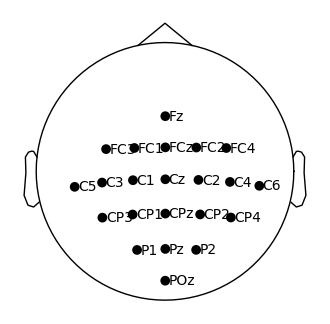

In [8]:
ref = xc.build_reference_artifacts(first, CFG, paths)
print("channel coords saved for", len(ref["channel_positions_3d_m"]), "electrodes")
print("class map:", ref["class_to_index"])
print("epoch:", ref["epoch"]["meaning"])

# quick sanity plot of electrode layout
import matplotlib.pyplot as plt, mne
fig, ax = plt.subplots(figsize=(4, 4))
mne.viz.plot_sensors(xc.make_info(ref["channel_names_in_order"], ref["channel_positions_3d_m"], ref["sampling_frequency_hz"]),
                     axes=ax, show=False, show_names=True)
plt.show()

## 7 · Train both models for every subject + predictions + explanations + comparison
Per subject this: splits the training session (stratified train/val, indices saved) → trains EEGNet (best-val-loss checkpoint, early stopping, resumable) → fits CSP+LDA → **reloads both from disk** → writes predictions → computes explanations (Integrated Gradients with real-trial baselines, channel/time attribution, band & time-frequency occlusion, activations) for the test trials → compares the two models on identical EEG.

Expect ≈ 3–8 min per subject on a T4 (longer on CPU). Safe to interrupt and re-run this cell.

In [9]:
summaries, failed = [], []
for sid in CFG["subjects"]:
    try:
        d = xc.load_subject_epochs(sid, CFG, paths)
        s = xc.process_subject(sid, d, CFG, paths, DEVICE, force_train=FORCE_TRAIN, force_explain=FORCE_EXPLAIN)
        summaries.append(s)
    except Exception as e:
        import traceback; traceback.print_exc()
        failed.append((sid, repr(e)))
        print(f"!! subject {sid} failed: {e}  (continuing; re-run the cell to retry)")
    finally:
        for v in ["d"]:
            globals().pop(v, None)
        xc.cleanup_gpu()
print("\nDone. Failed subjects:", failed or "none")

[subject 01] train 230 | val 58 | test 288 | X (576, 22, 513)
    ep   1  tr_loss 1.398 tr_acc 0.257 | val_loss 1.388 val_acc 0.241 | best ep 1
    ep  25  tr_loss 0.824 tr_acc 0.674 | val_loss 0.843 val_acc 0.621 | best ep 25
    ep  50  tr_loss 0.668 tr_acc 0.800 | val_loss 0.737 val_acc 0.672 | best ep 46
    ep  75  tr_loss 0.581 tr_acc 0.813 | val_loss 0.674 val_acc 0.776 | best ep 68
    ep 100  tr_loss 0.547 tr_acc 0.822 | val_loss 0.640 val_acc 0.741 | best ep 100
    ep 125  tr_loss 0.520 tr_acc 0.813 | val_loss 0.646 val_acc 0.724 | best ep 113
    ep 150  tr_loss 0.484 tr_acc 0.830 | val_loss 0.624 val_acc 0.724 | best ep 113
    ep 175  tr_loss 0.455 tr_acc 0.865 | val_loss 0.621 val_acc 0.724 | best ep 172
    ep 200  tr_loss 0.432 tr_acc 0.857 | val_loss 0.607 val_acc 0.741 | best ep 172
    ep 225  tr_loss 0.487 tr_acc 0.835 | val_loss 0.606 val_acc 0.724 | best ep 223
    ep 250  tr_loss 0.426 tr_acc 0.874 | val_loss 0.604 val_acc 0.741 | best ep 238
    ep 275  tr_loss

## 8 · Results overview

,EEGNet val,EEGNet test,EEGNet kappa,CSP+LDA val,CSP+LDA test,CSP+LDA kappa
subject,,,,,,
1,0.776,0.753,0.671,0.672,0.639,0.519
2,0.500,0.476,0.301,0.603,0.493,0.324
3,0.879,0.906,0.875,0.793,0.705,0.606
4,0.379,0.483,0.310,0.552,0.549,0.398
5,0.500,0.347,0.130,0.362,0.281,0.042
6,0.328,0.368,0.157,0.448,0.444,0.259
7,0.724,0.719,0.625,0.759,0.552,0.403
8,0.862,0.747,0.662,0.828,0.712,0.616
9,0.810,0.819,0.759,0.534,0.760,0.681


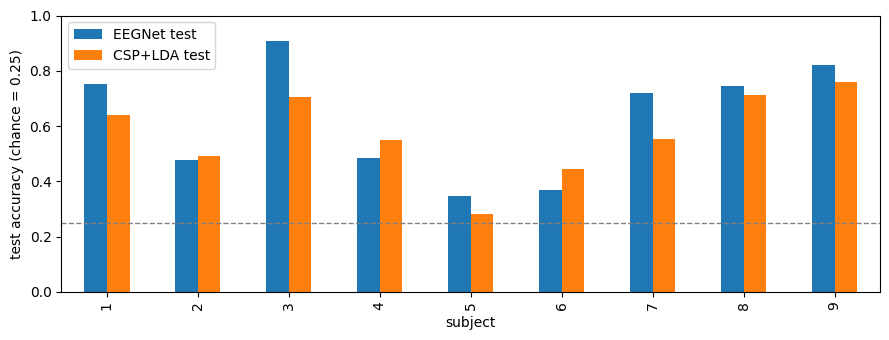

In [10]:
rows = []
for sid in CFG["subjects"]:
    p = paths.exp_dir(sid) / "metrics.json"
    if p.exists():
        m = xc.load_json(p)
        rows.append({"subject": sid,
                     "EEGNet val": m["eegnet_val"]["accuracy"], "EEGNet test": m["eegnet_test"]["accuracy"],
                     "EEGNet kappa": m["eegnet_test"]["kappa"],
                     "CSP+LDA val": m["csp_lda_val"]["accuracy"], "CSP+LDA test": m["csp_lda_test"]["accuracy"],
                     "CSP+LDA kappa": m["csp_lda_test"]["kappa"]})
res = pd.DataFrame(rows).set_index("subject")
res.loc["mean"] = res.mean()
xc.save_csv(res.reset_index(), paths.reports / "accuracy_summary.csv")
display(res.round(3))
ax = res.drop("mean")[["EEGNet test", "CSP+LDA test"]].plot.bar(figsize=(9, 3.5), ylim=(0, 1))
ax.axhline(0.25, color="gray", ls="--", lw=1); ax.set_ylabel("test accuracy (chance = 0.25)")
plt.tight_layout(); plt.savefig(paths.reports / "accuracy_by_subject.png", dpi=130); plt.show()

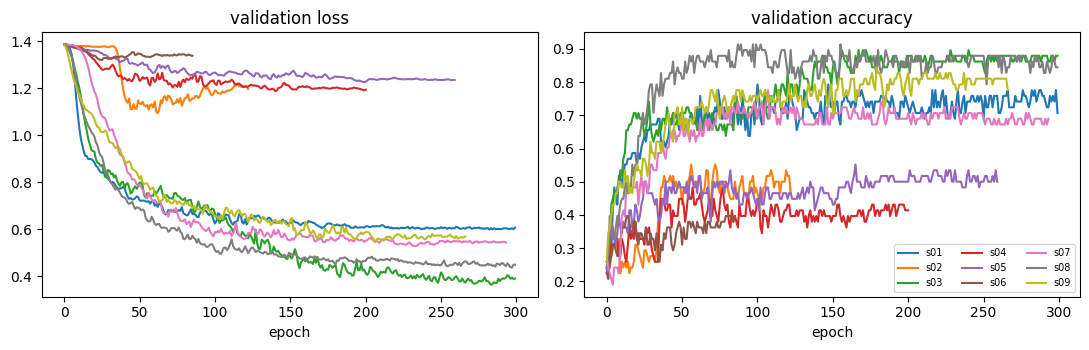

In [11]:
# training curves (EEGNet)
sids = [s for s in CFG["subjects"] if (paths.model_dir("eegnet", s) / "history.csv").exists()]
if sids:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for s in sids:
        h = pd.read_csv(paths.model_dir("eegnet", s) / "history.csv")
        axes[0].plot(h["val_loss"], label=f"s{s:02d}"); axes[1].plot(h["val_acc"], label=f"s{s:02d}")
    axes[0].set_title("validation loss"); axes[1].set_title("validation accuracy"); axes[1].legend(ncol=3, fontsize=7)
    for a in axes: a.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(paths.reports / "eegnet_training_curves.png", dpi=130); plt.show()

## 9 · Do the two models explain things the same way?
Computed on **identical test trials**. Each model is explained wrt *its own predicted class*.  
Similarity metrics (1 = identical, 0 = unrelated): channel-importance correlation, top-5 channel overlap, time-window correlation, frequency-band correlation, attribution-map correlation.

In [12]:
comp = pd.concat([pd.read_csv(paths.exp_dir(s) / "comparison.csv") for s in CFG["subjects"]
                  if (paths.exp_dir(s) / "comparison.csv").exists()], ignore_index=True)
xc.save_csv(comp, paths.reports / "comparison_all_subjects.csv")
def cat(r):
    if r.agree: return "agree & both correct" if r.eegnet_correct else "agree & both wrong"
    return "disagree"
comp["category"] = comp.apply(cat, axis=1)
simcols = ["channel_pearson", "channel_top5_overlap", "time_window_pearson", "freq_band_pearson", "attr_map_pearson"]
print(f"prediction agreement: {comp.agree.mean():.1%} of {len(comp)} trials")
summary = comp.groupby("category")[simcols + ["agree"]].agg("mean").round(3)
summary["n_trials"] = comp.groupby("category").size()
display(summary)
xc.save_csv(summary.reset_index(), paths.reports / "explanation_similarity_summary.csv")
print("IG completeness error (should be ~0):  EEGNet", comp.ig_delta_eegnet.abs().mean().round(4),
      "| CSP+LDA", comp.ig_delta_csp_lda.abs().mean().round(4))

prediction agreement: 55.6% of 2592 trials


,channel_pearson,channel_top5_overlap,time_window_pearson,freq_band_pearson,attr_map_pearson,agree,n_trials
category,,,,,,,
agree & both correct,0.310,0.357,0.190,0.244,0.256,1.0,1114
agree & both wrong,0.281,0.329,0.335,0.447,0.265,1.0,327
disagree,0.266,0.326,0.256,0.072,0.233,0.0,1151


IG completeness error (should be ~0):  EEGNet 0.0003 | CSP+LDA 0.0006


## 10 · Final artifact registry, manifest (SHA-256) and checklist audit

In [13]:
registry = {"dataset": xc.DATASET_NAME, "created": xc.now_iso(), "root": str(ROOT),
            "class_names": xc.CLASS_NAMES, "models": {}}
for sid in CFG["subjects"]:
    for m in ["eegnet", "csp_lda"]:
        p = paths.model_dir(m, sid) / "status.json"
        if p.exists() and xc.load_json(p).get("status") == "complete":
            registry["models"].setdefault(m, {})[f"{sid:02d}"] = {"dir": str(paths.model_dir(m, sid).relative_to(paths.root)),
                                                                   "checkpoint_id": xc.load_json(p)["checkpoint_id"]}
xc.save_json(paths.root / "registry.json", registry)
rows = xc.build_manifest(paths)
print(f"manifest: {len(rows)} files (sha256) -> manifest.json")
audit = xc.audit_artifacts(paths, CFG["subjects"])
xc.save_csv(audit, paths.reports / "artifact_audit.csv")
print(f"checklist: {int(audit.ok.sum())}/{len(audit)} items present")
display(audit[~audit.ok] if (~audit.ok).any() else pd.DataFrame({"all required artifacts present": ["OK"]}))
display(audit.groupby("section").ok.agg(["sum", "count"]))
os.sync()

manifest: 348 files (sha256) -> manifest.json
checklist: 177/177 items present


,all required artifacts present
0,OK


,sum,count
section,,
1 training,90,90
2 preprocessing,10,10
3 explanation,36,36
4 prediction,9,9
5 reference,11,11
6 comparison,9,9
env,3,3
explain support,9,9


## 11 · Restart-safe demo: load a *new* EEG signal from Drive artifacts only
This cell uses **only files on Drive** (`xbci_core.py`, saved models, reference) — exactly what the Streamlit app will do.  
Pick a subject, a trial (here a test trial acts as the "new" signal) and the model(s).

eegnet   -> predicted left_hand   (true: left_hand) | probs [0.083 0.664 0.243 0.01 ] | ckpt eegnet_s01_ep283_849f6d8d
csp_lda  -> predicted left_hand   (true: left_hand) | probs [0.002 0.986 0.012 0.   ] | ckpt csp_lda_s01_23bf711d


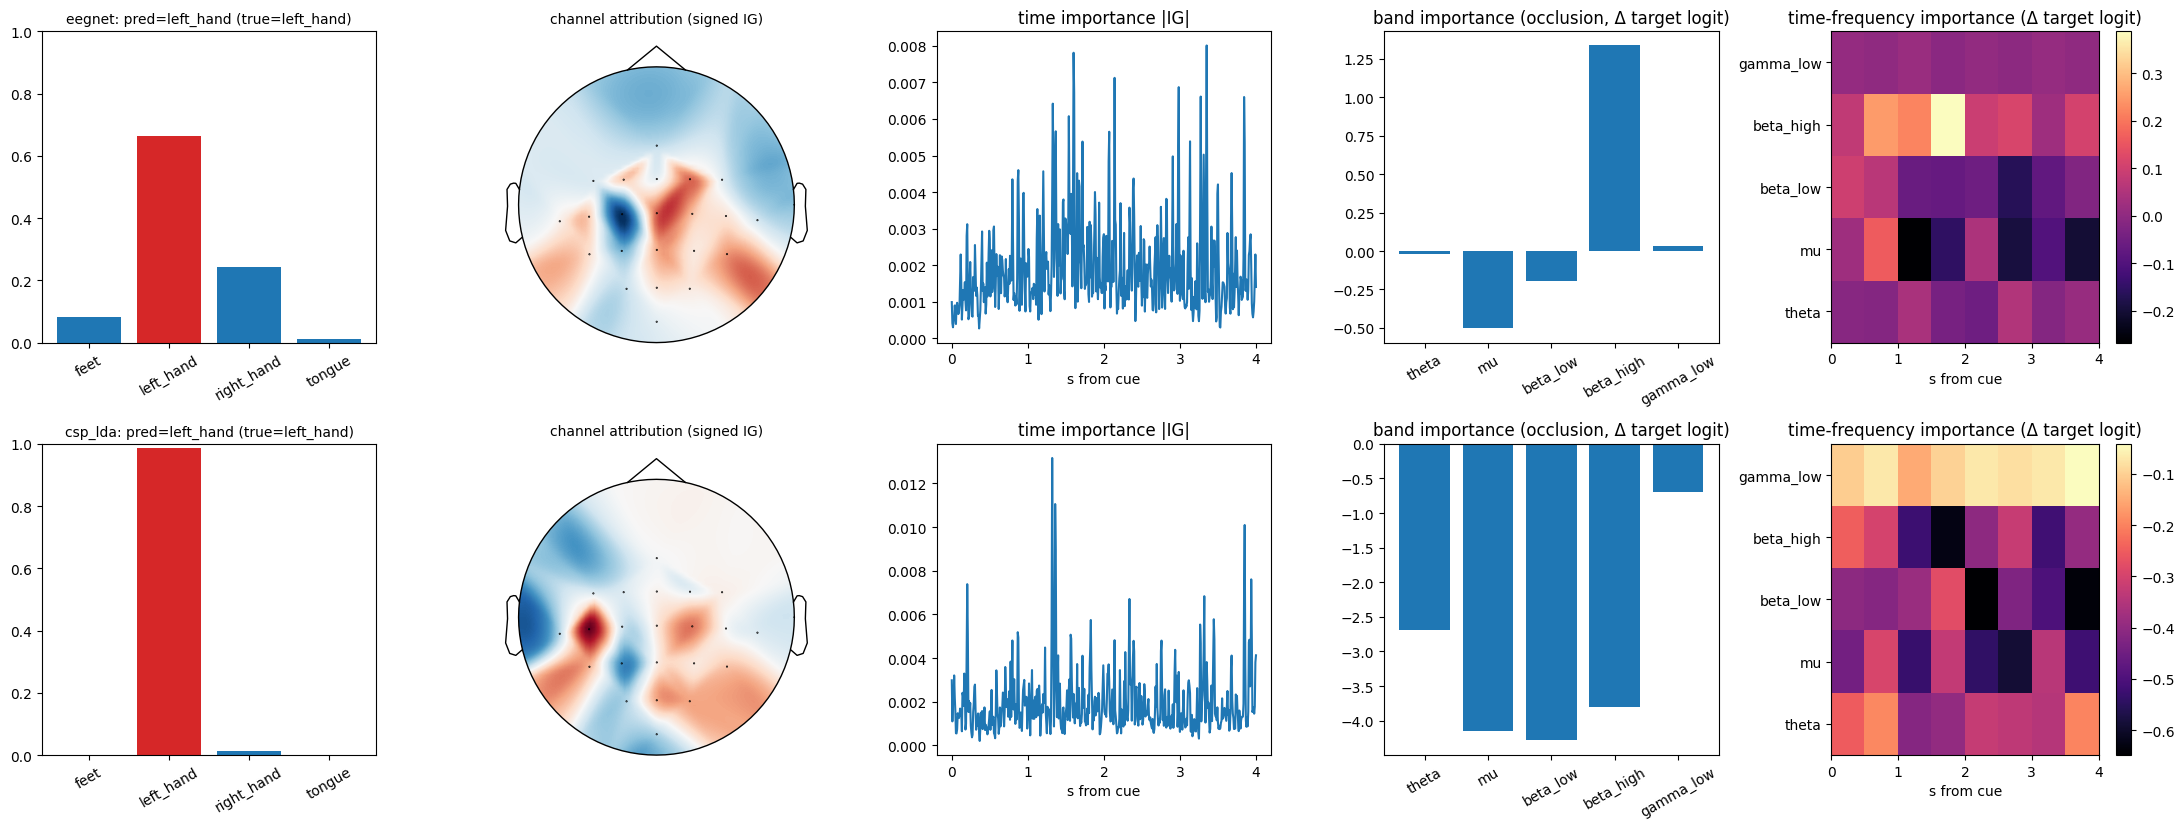

In [14]:
SUBJECT, TRIAL_IN_TEST, MODELS = 1, 10, ["eegnet", "csp_lda"]        # MODELS: one or both

d = xc.load_subject_epochs(SUBJECT, CFG, paths)
te = np.load(paths.exp_dir(SUBJECT) / "split_indices.npz")["test_idx"]
x = d["X"][te[TRIAL_IN_TEST]]; true = xc.CLASS_NAMES[d["y"][te[TRIAL_IN_TEST]]]
del d
ref = xc.load_reference(paths)
out = xc.explain_single(paths, SUBJECT, MODELS, x, DEVICE)
for m, r in out.items():
    print(f"{m:8s} -> predicted {xc.CLASS_NAMES[r['pred']]:11s} (true: {true}) | probs {np.round(r['probs'], 3)} | ckpt {r['checkpoint_id']}")
fig = xc.plot_comparison_dashboard(out, x, ref, model_names=MODELS, true_label=true,
                                   save_path=paths.reports / "demo_dashboard.png")
plt.show()

,name,type,output_shape,n_params
0,conv_temporal,Conv2d,"[8, 22, 513]",512
1,bn1,BatchNorm2d,"[8, 22, 513]",16
2,conv_depthwise,Conv2d,"[16, 1, 513]",352
3,bn2,BatchNorm2d,"[16, 1, 513]",32
4,act1,ELU,"[16, 1, 513]",0
5,pool1,AvgPool2d,"[16, 1, 128]",0
6,drop1,Dropout,"[16, 1, 128]",0
7,conv_sep_depth,Conv2d,"[16, 1, 128]",256
8,conv_sep_point,Conv2d,"[16, 1, 128]",256
9,bn3,BatchNorm2d,"[16, 1, 128]",32


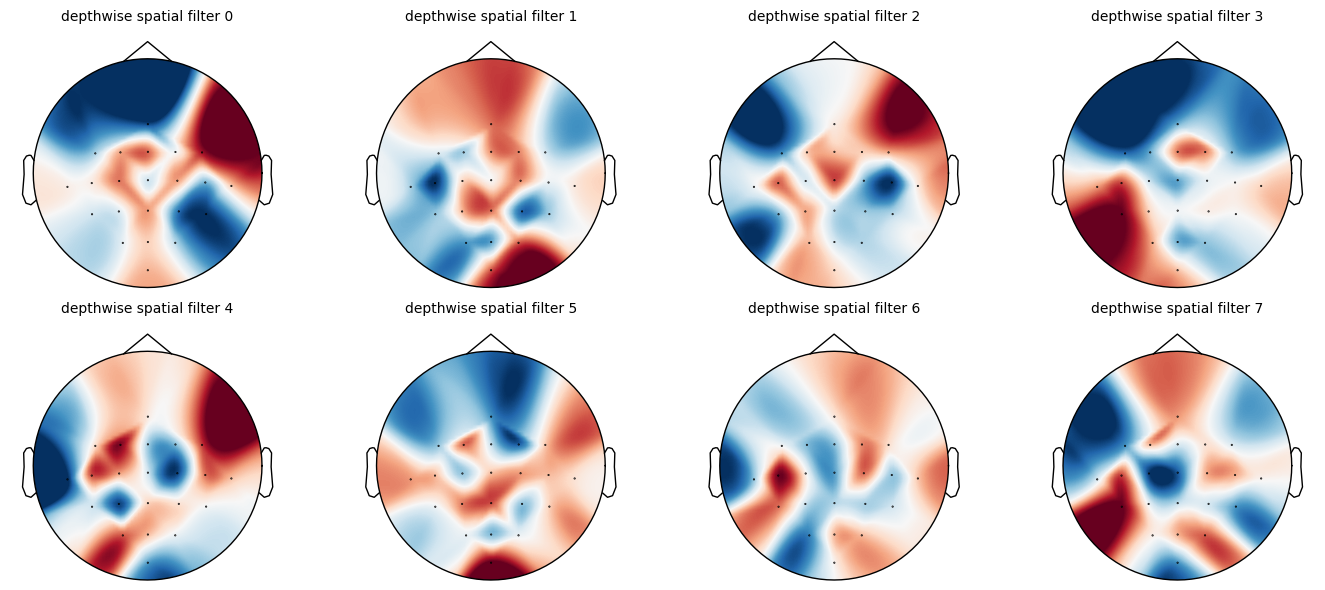

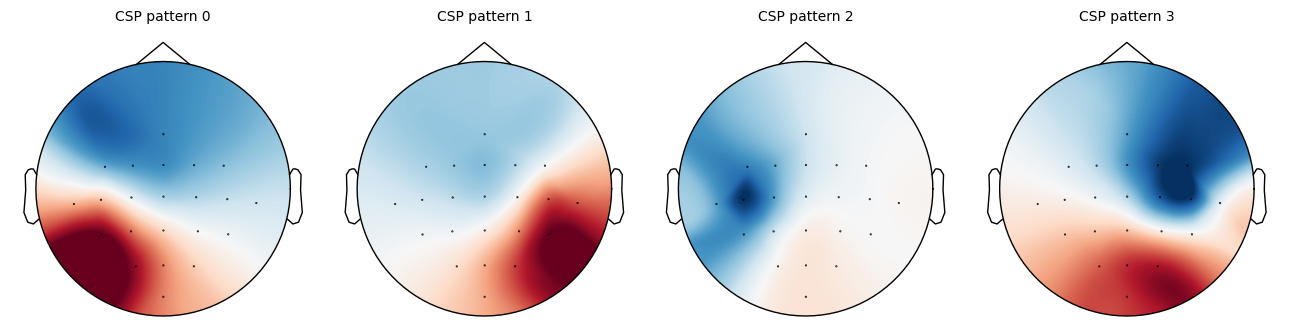

LDA coef shape (classes x CSP features): (4, 8) | intercept: [-1.85 -4.44 -6.43 -3.16]


In [15]:
# Model internals available for the "why" panel
if "eegnet" in out:
    ls = xc.load_json(paths.model_dir("eegnet", SUBJECT) / "layer_summary.json")
    display(pd.DataFrame(ls)[["name", "type", "output_shape", "n_params"]])
    lw = np.load(paths.model_dir("eegnet", SUBJECT) / "layer_weights.npz")
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for i, ax in enumerate(axes.ravel()):
        xc.plot_topomap(ax, lw["derived__spatial_filters"][i], ref["channel_names_in_order"],
                        ref["channel_positions_3d_m"], ref["sampling_frequency_hz"], title=f"depthwise spatial filter {i}")
    plt.tight_layout(); plt.show()
if "csp_lda" in out:
    z = np.load(paths.model_dir("csp_lda", SUBJECT) / "csp_lda_params.npz")
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
    for i, ax in enumerate(axes):
        xc.plot_topomap(ax, z["patterns"][i], ref["channel_names_in_order"], ref["channel_positions_3d_m"],
                        ref["sampling_frequency_hz"], title=f"CSP pattern {i}")
    plt.tight_layout(); plt.show()
    print("LDA coef shape (classes x CSP features):", z["lda_coef"].shape, "| intercept:", np.round(z["lda_intercept"], 2))

## 12 · (Optional) SHAP explanations
Set `RUN_SHAP = True` to compute SHAP values (GradientExplainer, background = saved baseline pool). Wrapped in `try/except`; SHAP results depend on the method and background data, so they are *recomputed* rather than stored.

In [16]:
RUN_SHAP = False
if RUN_SHAP:
    try:
        pip("shap")
        import shap
        pool = np.load(paths.exp_dir(SUBJECT) / "baseline_pool.npz")["X"]
        b = xc.load_bundle(paths, "eegnet", SUBJECT, DEVICE)
        bg = torch.as_tensor(pool[:16], dtype=torch.float32, device=DEVICE)
        expl = shap.GradientExplainer(b["model"], bg)
        sv = expl.shap_values(torch.as_tensor(x[None], dtype=torch.float32, device=DEVICE))
        sv = np.stack(sv, -1) if isinstance(sv, list) else sv
        print("SHAP values shape:", sv.shape)       # (1, C, T, n_classes)
    except Exception as e:
        print("SHAP skipped:", e)

## 13 · Zip & download the entire artifact folder
Zips the whole `XBCI_BNCI2014_001/` folder (same structure as on Drive) into one file, keeps a copy on Drive, and triggers a browser download.  
`INCLUDE_RAW=False` skips `raw_mne_data/` (the re-downloadable raw `.mat` files) to make the zip much smaller.

In [17]:
INCLUDE_RAW = True          # False -> skip raw_mne_data/ (smaller zip)
DOWNLOAD = True             # False -> only create the zip on Drive
import zipfile, os, time
os.sync()
zip_name = "XBCI_BNCI2014_001" + ("" if INCLUDE_RAW else "_no_raw") + ".zip"
zip_local = "/content/" + zip_name                       # build on local disk (fast), then copy to Drive
n_files, t0 = 0, time.time()
with zipfile.ZipFile(zip_local, "w", zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as z:
    for p in sorted(paths.root.rglob("*")):
        if not p.is_file() or p.name.endswith(".tmp") or p.suffix == ".zip":
            continue
        if not INCLUDE_RAW and "raw_mne_data" in p.parts:
            continue
        z.write(p, Path(paths.root.name) / p.relative_to(paths.root))   # keeps top-level folder name
        n_files += 1
size_mb = os.path.getsize(zip_local) / 1e6
print(f"zipped {n_files} files -> {zip_local}  ({size_mb:.0f} MB, {time.time()-t0:.0f}s)")
with zipfile.ZipFile(zip_local) as z:                       # verify integrity + show structure
    assert z.testzip() is None, "corrupt zip"
    tops = sorted({"/".join(n.split("/")[:2]) for n in z.namelist()})
print("top-level contents:", tops)
try:
    shutil.copy(zip_local, paths.root.parent / zip_name)
    print("copy kept on Drive:", paths.root.parent / zip_name)
except Exception as e:
    print("could not copy zip to Drive:", e)
if DOWNLOAD:
    try:
        from google.colab import files
        files.download(zip_local)
    except Exception as e:
        print("Browser download failed (large files can time out) -> grab the zip from Drive instead:", e)

zipped 392 files -> /content/XBCI_BNCI2014_001.zip  (1987 MB, 86s)
top-level contents: ['XBCI_BNCI2014_001/code', 'XBCI_BNCI2014_001/data_processed', 'XBCI_BNCI2014_001/env', 'XBCI_BNCI2014_001/experiments', 'XBCI_BNCI2014_001/manifest.json', 'XBCI_BNCI2014_001/models', 'XBCI_BNCI2014_001/raw_mne_data', 'XBCI_BNCI2014_001/reference', 'XBCI_BNCI2014_001/registry.json', 'XBCI_BNCI2014_001/reports']
copy kept on Drive: /content/drive/MyDrive/XBCI_BNCI2014_001.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What you can recover after the runtime ends (section 7 of your list)
| Item | After restart |
|---|---|
| Weights, architecture, checkpoints, optimizer state, history, configs, seeds | ✅ on Drive |
| Layer weights, CSP filters/patterns, LDA coef/intercept | ✅ on Drive |
| Predictions, probabilities, comparison records, metrics | ✅ on Drive |
| IG / channel / time / frequency / TF attributions (test trials) | ✅ saved; **any new signal** → recomputed in seconds by `explain_single` |
| Topographic maps | ✅ recreated from saved coordinates + attributions |
| SHAP | recomputed (method/background dependent; background pool is saved) |
| Layer activations | ✅ for a class-balanced subset + energy for all explained trials; any signal → recomputed |
| Exact versions | ✅ `env/versions.json`, `env/requirements_freeze.txt`; code in `code/xbci_core.py` |

**Next step:** the Streamlit app imports `xbci_core` from `code/`, reads `reference/` + `models/` + `experiments/`, and calls `explain_single(...)` for one or both models.